In [3]:
from sklearn.datasets import load_iris
iris = load_iris()

In [23]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# 1. 数据集加载与特征矩阵构建
# 封装为结构化 DataFrame 并绑定目标列
iris_df = pd.DataFrame(data=np.c_[iris['data'], iris['target']],
columns=iris['feature_names'] + ['target'])

# 基于特征空间高斯微扰 (Gaussian Perturbation) 的样本增强策略
def augment_data(X, y, num_new_samples=100):
    new_X = []
    new_y = []
    for _ in range(num_new_samples):
        # 随机抽取基准样本
        index = np.random.randint(0, len(X))
        sample = X[index]
        label = y[index]
        # 生成 N(0, 0.1) 高斯分布扰动噪声
        noise = np.random.normal(0, 0.1, size=sample.shape)
        new_sample = sample + noise
        new_X.append(new_sample)
        new_y.append(label)
    new_X = np.array(new_X)
    new_y = np.array(new_y)
    # 垂直拼接扩展特征矩阵与标签向量
    augmented_X = np.vstack((X, new_X))
    augmented_y = np.hstack((y, new_y))
    return augmented_X, augmented_y

# 执行样本集扩增
augmented_X, augmented_y = augment_data(X, y, num_new_samples=200)

print("原始数据集样本数:", len(X))
print("扩大后数据集样本数:", len(augmented_X))

# 2. 数据集描述性统计与结构探查
print("数据基本信息：")
iris_df.info()
# 提取样本总量与特征维度
rows, columns = iris_df.shape

# 3. 缺失值检测与均值插补
# 全局缺失率检测
if iris_df.isnull().any().any():
    # 缺失样本采用列均值插补策略
    iris_df = iris_df.fillna(iris_df.mean())
else:
    print("数据集中不存在缺失值。")

# 4. 异常点检测与截断处理
# 基于拉依达准则 (Z-Score > 3) 识别离群异常样本
for column in iris_df.columns[:-1]:  # 最后一列是目标列，不处理
    z_scores = np.abs((iris_df[column] - iris_df[column].mean()) / iris_df[column].std())
    # 截断异常值并赋予对应列均值
    iris_df.loc[z_scores > 3, column] = iris_df[column].mean()

# 5. 特征标准化 (StandardScaler)
# 解耦特征矩阵与目标标签
X = iris_df.drop('target', axis=1)
y = iris_df['target']
# 执行标准差归一化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 6. 训练集与测试集划分
# 按 80/20 比例划分并固定随机种子
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 输出预处理后特征与标签矩阵维度
print("处理后训练集特征形状：", X_train.shape)
print("处理后训练集标签形状：", y_train.shape)
print("处理后测试集特征形状：", X_test.shape)
print("处理后测试集标签形状：", y_test.shape)

原始数据集样本数: 60
扩大后数据集样本数: 260
数据基本信息：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB
数据集中不存在缺失值。
处理后训练集特征形状： (120, 4)
处理后训练集标签形状： (120,)
处理后测试集特征形状： (30, 4)
处理后测试集标签形状： (30,)


过采样后训练集类别分布: Counter({0: 41, 1: 41, 2: 41})


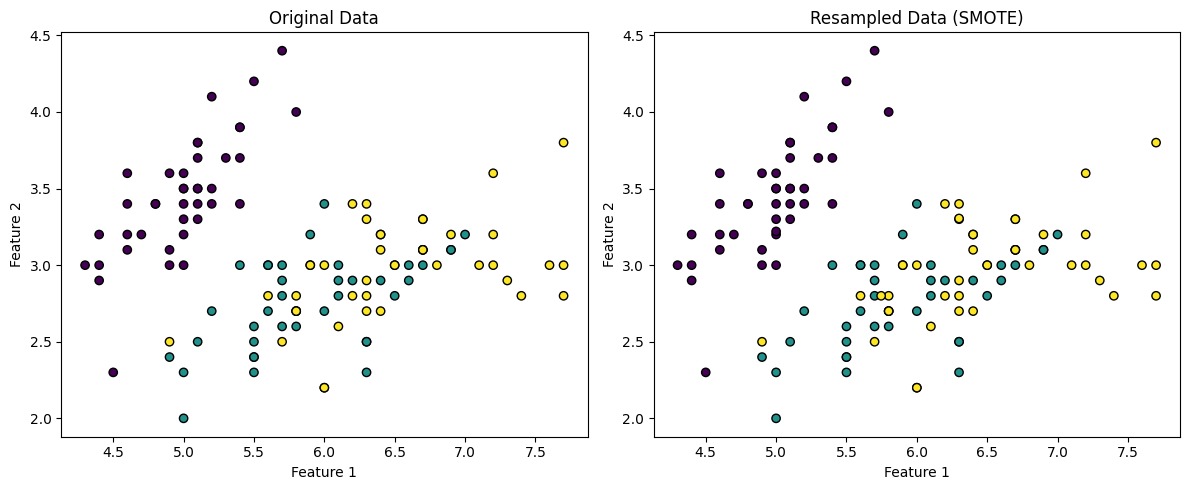

In [12]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
from collections import Counter
# 实施 SMOTE 边界过采样
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# 检验过采样平衡后类别先验分布
print("过采样后训练集类别分布:", Counter(y_train_resampled))

# 二维特征子空间样本分布对比可视化
plt.figure(figsize=(12, 5))

# 投影绘制原始样本特征空间分布
plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='k')
plt.title('Original Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

# 投影绘制过采样后合成样本分布
plt.subplot(1, 2, 2)
plt.scatter(X_train_resampled[:, 0], X_train_resampled[:, 1], c=y_train_resampled, cmap='viridis', edgecolor='k')
plt.title('Resampled Data (SMOTE)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    return accuracy, precision, recall, f1


# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target


print("原始数据集样本数:", len(X))
print("扩大后数据集样本数:", len(augmented_X))
# 构建二分类不平衡分布（过滤类别 2 并欠采样类别 0）
X = X[y != 2]
y = y[y != 2]
# 类别 0 人工欠采样至 10 个样本
np.random.seed(42)
class_0_indices = np.where(y == 0)[0]
selected_indices = np.random.choice(class_0_indices, size=10, replace=False)
other_indices = np.where(y != 0)[0]
new_indices = np.concatenate([selected_indices, other_indices])
X = X[new_indices]
y = y[new_indices]

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 统计不平衡训练集类别分布
print("原始训练集类别分布:", Counter(y_train))

# 实施 SMOTE 边界过采样
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# 检验过采样平衡后类别先验分布
print("过采样后训练集类别分布:", Counter(y_train_resampled))

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)
lr_accuracy, lr_precision, lr_recall, lr_f1 = evaluate_model(lr_model, X_test, y_test)
print("\n逻辑回归模型评估结果:")
print(f"准确率: {lr_accuracy:.4f}")
print(f"精确率: {lr_precision:.4f}")
print(f"召回率: {lr_recall:.4f}")
print(f"F1 分数: {lr_f1:.4f}")

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_resampled, y_train_resampled)
lr_accuracy, lr_precision, lr_recall, lr_f1 = evaluate_model(lr_model, X_test, y_test)
print("\n逻辑回归模型评估结果:")
print(f"准确率: {lr_accuracy:.4f}")
print(f"精确率: {lr_precision:.4f}")
print(f"召回率: {lr_recall:.4f}")
print(f"F1 分数: {lr_f1:.4f}")



原始数据集样本数: 150


In [39]:
# 支持向量机 (SVM) 分类器
svm_model = SVC(random_state=42)
svm_model.fit(X_train_resampled, y_train_resampled)
svm_accuracy, svm_precision, svm_recall, svm_f1 = evaluate_model(svm_model, X_test, y_test)
print("\nSVM模型评估结果:")
print(f"准确率: {svm_accuracy:.4f}")
print(f"精确率: {svm_precision:.4f}")
print(f"召回率: {svm_recall:.4f}")
print(f"F1 分数: {svm_f1:.4f}")


SVM模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000


In [10]:
# 高斯朴素贝叶斯分类器


nb_model = GaussianNB()
nb_model.fit(X_train_resampled, y_train_resampled)
nb_accuracy, nb_precision, nb_recall, nb_f1 = evaluate_model(nb_model, X_test, y_test)
print("\n朴素贝叶斯模型评估结果:")
print(f"准确率: {nb_accuracy:.4f}")
print(f"精确率: {nb_precision:.4f}")
print(f"F1 分数: {nb_f1:.4f}")
# 基于 SHAP 解释框架构建模型特征归因
# 构建 TreeExplainer 解释器
explainer = shap.Explainer(nb_model)



In [29]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)
rf_accuracy, rf_precision, rf_recall, rf_f1 = evaluate_model(rf_model, X_test, y_test)
print("\n随机森林模型评估结果:")
print(f"准确率: {rf_accuracy:.4f}")
print(f"精确率: {rf_precision:.4f}")
print(f"召回率: {rf_recall:.4f}")
print(f"F1 分数: {rf_f1:.4f}")


随机森林模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000


In [30]:

# XGBoost 梯度提升分类器
xgb_model = xgb.XGBClassifier(random_state=42)
xgb_model.fit(X_train_resampled, y_train_resampled)
xgb_accuracy, xgb_precision, xgb_recall, xgb_f1 = evaluate_model(xgb_model, X_test, y_test)
print("\nXGBoost模型评估结果:")
print(f"准确率: {xgb_accuracy:.4f}")
print(f"精确率: {xgb_precision:.4f}")
print(f"召回率: {xgb_recall:.4f}")
print(f"F1 分数: {xgb_f1:.4f}")


XGBoost模型评估结果:
准确率: 1.0000
精确率: 1.0000
召回率: 1.0000
F1 分数: 1.0000


In [31]:
# LightGBM 决策树分类器
lgb_model = lgb.LGBMClassifier(random_state=42)
lgb_model.fit(X_train_resampled, y_train_resampled)
lgb_accuracy, lgb_precision, lgb_recall, lgb_f1 = evaluate_model(lgb_model, X_test, y_test)
print("\nLightGBM模型评估结果:")
print(f"准确率: {lgb_accuracy:.4f}")
print(f"精确率: {lgb_precision:.4f}")
print(f"召回率: {lgb_recall:.4f}")
print(f"F1 分数: {lgb_f1:.4f}")

[LightGBM] [Info] Number of positive: 40, number of negative: 40
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000046 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 82
[LightGBM] [Info] Number of data points in the train set: 80, number of used features: 4
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posi

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000060 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 91
[LightGBM] [Info] Number of data points in the train set: 120, number of used features: 4
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.073920
[LightGBM] [Info] Start training from score -1.123930
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

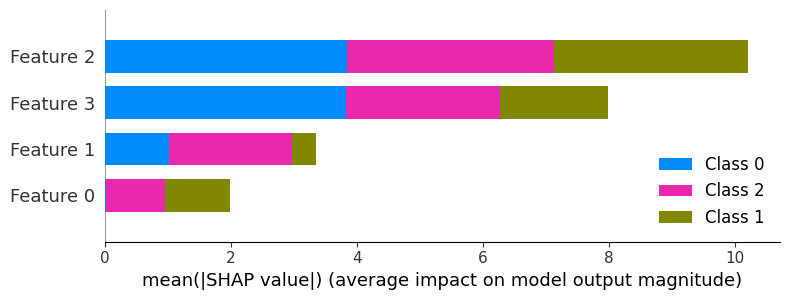

In [7]:
# 计算样本的 Shapley 归因值用于模型归因解释
import shap
import lightgbm as lgb

# 基于调优参数训练 LightGBM 基准模型
best_params = {'learning_rate': 0.1, 'n_estimators': 200, 'num_leaves': 63}
lgb_best = lgb.LGBMClassifier(**best_params)
lgb_best.fit(X_train, y_train)

# 基于 SHAP 解释框架构建模型特征归因
# 构建 TreeExplainer 解释器
explainer = shap.Explainer(lgb_best)

# 估算全局 Shapley 归因值
shap_values = explainer.shap_values(X_train)
# 绘制多分类 SHAP 汇总分布图 (Beeswarm)
shap.summary_plot(shap_values, X_train)

In [44]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 构建 Bagging 集成分类器
base_model = GaussianNB()
bagging_model = BaggingClassifier(base_estimator=base_model, n_estimators=10, random_state=42)

# 拟合集成分类模型
bagging_model.fit(X_train, y_train)

# 评估预测准确率指标
y_pred = bagging_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"使用Bagging方法后朴素贝叶斯模型的准确率: {accuracy:.4f}")
print(f"精确率: {xgb_precision:.4f}")
print(f"F1 分数: {xgb_f1:.4f}")

使用Bagging方法后朴素贝叶斯模型的准确率: 1.0000
精确率: 1.0000
F1 分数: 1.0000


site-packages/sklearn\ensemble\_base.py:156: FutureWarning: `base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.
  warnings.warn(


In [5]:
import shap
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GaussianNB()
model.fit(X_train, y_train)

explainer = shap.Explainer(model.predict_proba, X_train)
shap_values = explainer(X_test)

sample_index = 0  # 确保是整数索引
shap.force_plot(explainer.expected_value[0], shap_values[sample_index].values[:, 0], X_test[sample_index], feature_names=iris.feature_names)

In [7]:
pip install --upgrade shap

Note: you may need to restart the kernel to use updated packages.


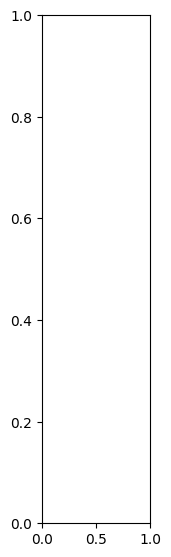

In [2]:
import shap
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
import matplotlib.pyplot as plt

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 拟合高斯朴素贝叶斯基分类器
model = GaussianNB()
model.fit(X_train, y_train)

# 构建 SHAP Explainer
explainer = shap.Explainer(model.predict_proba, X_train)

# 计算样本的 Shapley 归因值
shap_values = explainer(X_test)

# 可视化所有类别的 SHAP 汇总图
shap.summary_plot(shap_values.values, X_test, feature_names=iris.feature_names)

# 可视化单个样本的 SHAP 力导向图（以第一个样本为例）
sample_index = 0
shap.force_plot(explainer.expected_value[0], shap_values[sample_index].values[:, 0], X_test[sample_index], feature_names=iris.feature_names)

# 如果在 Jupyter Notebook 中运行，上述 force_plot 可以直接显示
# 如果在 Python 脚本中运行，需要使用 matplotlib 显示
plt.show()

In [3]:
import shap
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GaussianNB()
model.fit(X_train, y_train)

explainer = shap.Explainer(model.predict_proba, X_train)
shap_values = explainer(X_test)

sample_index = 0  # 整数索引
shap.force_plot(explainer.expected_value[0], shap_values[sample_index].values[:, 0], X_test[sample_index], feature_names=iris.feature_names)

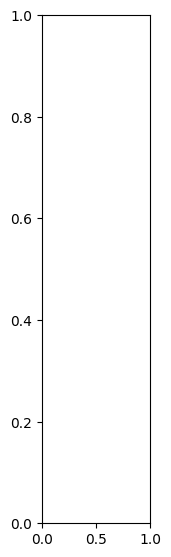

In [4]:
import shap
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
import matplotlib.pyplot as plt

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 训练 SVM 模型
model = SVC(probability=True, random_state=42)
model.fit(X_train, y_train)

# 构建 SHAP Explainer
explainer = shap.Explainer(model.predict_proba, X_train)

# 计算样本的 Shapley 归因值
shap_values = explainer(X_test)

# 全局特征重要性可视化（SHAP 汇总图）
shap.summary_plot(shap_values.values, X_test, feature_names=iris.feature_names)

# 单个样本的特征贡献可视化（以第一个样本为例）
sample_index = 0
# 对于多分类问题，选择一个类别（例如类别 0）
class_index = 0
shap.force_plot(explainer.expected_value[class_index], shap_values[sample_index].values[:, class_index],
                X_test[sample_index], feature_names=iris.feature_names)

# 如果在 Python 脚本中运行，需要使用 matplotlib 显示图形
plt.show()

`base_estimator` was renamed to `estimator` in version 1.2 and will be removed in 1.4.


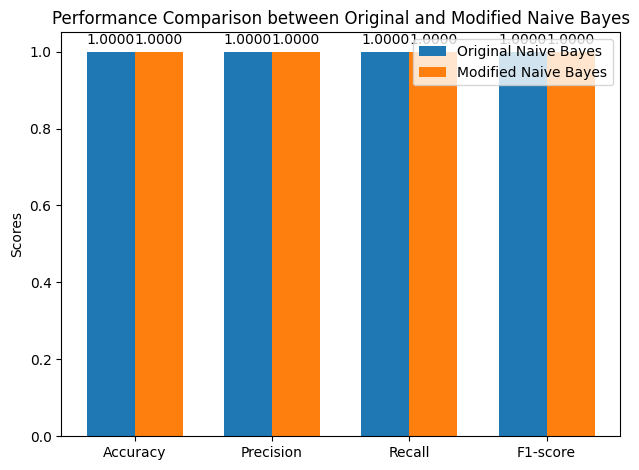

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 加载鸢尾花数据集
iris = load_iris()
X = iris.data
y = iris.target

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 原始朴素贝叶斯模型
original_model = GaussianNB()
original_model.fit(X_train, y_train)
original_y_pred = original_model.predict(X_test)

# 计算原始模型的评估指标
original_accuracy = accuracy_score(y_test, original_y_pred)
original_precision = precision_score(y_test, original_y_pred, average='weighted')
original_recall = recall_score(y_test, original_y_pred, average='weighted')
original_f1 = f1_score(y_test, original_y_pred, average='weighted')

# 修改后的朴素贝叶斯模型（特征缩放 + Bagging）
# 特征缩放
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 构建 Bagging 集成分类器
base_model = GaussianNB()
modified_model = BaggingClassifier(base_estimator=base_model, n_estimators=10, random_state=42)
modified_model.fit(X_train_scaled, y_train)
modified_y_pred = modified_model.predict(X_test_scaled)

# 计算修改后模型的评估指标
modified_accuracy = accuracy_score(y_test, modified_y_pred)
modified_precision = precision_score(y_test, modified_y_pred, average='weighted')
modified_recall = recall_score(y_test, modified_y_pred, average='weighted')
modified_f1 = f1_score(y_test, modified_y_pred, average='weighted')

# 可视化性能差异
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
original_scores = [original_accuracy, original_precision, original_recall, original_f1]
modified_scores = [modified_accuracy, modified_precision, modified_recall, modified_f1]

x = np.arange(len(metrics))  # 标签位置
width = 0.35  # 柱状图宽度

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, original_scores, width, label='Original Naive Bayes')
rects2 = ax.bar(x + width/2, modified_scores, width, label='Modified Naive Bayes')

# 添加文本标签和标题
ax.set_ylabel('Scores')
ax.set_title('Performance Comparison between Original and Modified Naive Bayes')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()

def autolabel(rects):
    """在每个柱子上添加数值标签"""
    for rect in rects:
        height = rect.get_height()
        ax.annotate('{:.4f}'.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()

plt.show()